In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime

In [2]:

# Configurações
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)

In [3]:
print("="*80)
print("ANÁLISE EXPLORATÓRIA DE DADOS - HEPATITES VIRAIS (SINAN) - VERSÃO CORRIGIDA")
print("="*80)

ANÁLISE EXPLORATÓRIA DE DADOS - HEPATITES VIRAIS (SINAN) - VERSÃO CORRIGIDA


# Preparação dos dados


#### 1. CARREGAMENTO E FILTROS INICIAIS


In [6]:
from ipywidgets import interact

print("\n" + "="*80)
print("ETAPA 1: CARREGAMENTO E FILTROS INICIAIS")
print("="*80)

df = pd.read_parquet("../sinan_parquet/SINAN_HEPA.parquet", engine="fastparquet")



ETAPA 1: CARREGAMENTO E FILTROS INICIAIS


Dicionário completo de variáveis do SINAN - Hepatites Virais

In [8]:
# 🔹 df_clean já carregado anteriormente
print(f"✅ Dataset carregado com {df.shape[0]} linhas e {df.shape[1]} colunas.\n")

# 1️⃣ Dicionário oficial de variáveis e descrições
descricao_variaveis = {

    # --- Identificação e Notificação ---
    "TP_NOT": "Tipo de notificação (1=Individual, 2=Surto)",
    "ID_AGRAVO": "Código do agravo (ex: B16 - Hepatite viral aguda B)",
    "DT_NOTIFIC": "Data da notificação do caso",
    "SEM_NOT": "Semana epidemiológica da notificação",
    "NU_ANO": "Ano da notificação",
    "SG_UF_NOT": "Sigla da UF onde o caso foi notificado",
    "ID_MUNICIP": "Código IBGE do município de notificação",
    "ID_REGIONA": "Código da regional de saúde da notificação",

    # --- Dados do Paciente ---
    "NU_IDADE_N": "Idade do paciente em anos",
    "CS_SEXO": "Sexo (1=Masculino, 2=Feminino, 9=Ignorado)",
    "CS_GESTANT": "Situação gestacional (1º, 2º, 3º trimestre, não ou não se aplica)",
    "CS_RACA": "Raça/Cor (1=Branca, 2=Preta, 3=Amarela, 4=Parda, 5=Indígena, 9=Ignorado)",
    "CS_ESCOL_N": "Escolaridade (0 a 9, de Analfabeto a Superior Completo)",
    "SG_UF": "Sigla da UF de residência",
    "ID_MN_RESI": "Código IBGE do município de residência",
    "ID_RG_RESI": "Código da regional de residência",
    "ID_PAIS": "Código do país de residência",
    "ID_OCUPA_N": "Código CBO da ocupação do paciente",

    # --- Investigação e Encerramento ---
    "DT_INVEST": "Data de início da investigação do caso",
    "CLASSI_FIN": "Classificação final (1=Confirmado, 2=Descartado, etc.)",
    "DT_ENCERRA": "Data de encerramento da investigação",
    "ano": "Ano do encerramento (derivado de DT_ENCERRA)",

    # --- Diagnóstico e Tipo ---
    "DT_DIAG": "Data do diagnóstico laboratorial",
    "SEM_DIAG": "Semana epidemiológica do diagnóstico",
    "HEPATITE_N": "Tipo de hepatite (A, B, C, D, E)",
    "HEPATITA": "Marcador de hepatite A (IgM anti-HAV positivo)",
    "HEPATITB": "Marcador de hepatite B (HBsAg positivo)",
    "FORMA": "Forma clínica (01=Aguda, 02=Crônica/Portador, 03=Fulminante)",

    # --- Fatores e Comportamentos de Risco ---
    "INSTITUCIO": "Paciente institucionalizado (ex: presídio, abrigo)",
    "HIV": "Co-infecção por HIV",
    "OUTRA_DST": "Outra DST associada",
    "SEXUAL": "Comportamento sexual de risco",
    "DOMICILI": "Contato domiciliar com portador de hepatite",
    "OCUPACIO": "Exposição ocupacional a sangue/material biológico",
    "MEDICAMENT": "Uso de medicamentos injetáveis não prescritos",
    "TATU_PIER": "Tatuagem ou piercing",
    "MATBIOLOGI": "Manipulação de material biológico",
    "INAL_CRACK": "Uso de drogas inaladas (crack, cocaína)",
    "ACUPUNTURA": "Fez acupuntura",
    "TRANSFUSAO": "Recebeu transfusão de sangue",
    "INJETAVEIS": "Uso de drogas injetáveis",
    "CIRURGICO": "Procedimentos cirúrgicos prévios",
    "AGUA_ALIME": "Ingestão de água/alimentos contaminados",
    "DENTARIO": "Atendimento odontológico recente",
    "TRESMAIS": "Mais de 3 parceiros sexuais",
    "HEMODIALIS": "Paciente em hemodiálise",
    "TRANSPLA": "Paciente transplantado",
    "OUTRAS": "Outras exposições não listadas",
    "DT_ACIDENT": "Data de provável exposição/acidente",

    # --- Localidades de Infecção ---
    "CO_UF_EXP": "UF provável de infecção (1ª hipótese)",
    "CO_MUN_EXP": "Município provável de infecção (1ª hipótese)",
    "CO_UF_EX2": "UF provável de infecção (2ª hipótese)",
    "CO_MUN_EX2": "Município provável de infecção (2ª hipótese)",
    "CO_UF_EX3": "UF provável de infecção (3ª hipótese)",
    "CO_MUN_EX3": "Município provável de infecção (3ª hipótese)",
    "BANCOSANGU": "Frequentou/trabalhou em banco de sangue",

    # --- Exames laboratoriais ---
    "RES_HBSAG": "Resultado do teste HBsAg (hepatite B)",
    "RE_ANTIHBC": "Resultado do teste Anti-HBc (hepatite B)",
    "RE_ANTIHCV": "Resultado do teste Anti-HCV (hepatite C)",
    "DT_COLETA": "Data da coleta da amostra",
    "ANTIHAVIGM": "Teste Anti-HAV IgM (hepatite A)",
    "ANTIHBS": "Teste Anti-HBs (imunidade hepatite B)",
    "ANTIHDVIGM": "Teste Anti-HDV IgM (hepatite D)",
    "AGHBS": "Antígeno HBs (hepatite B)",
    "AGHBE": "Antígeno HBe (hepatite B, replicação viral)",
    "ANTIHEVIGM": "Teste Anti-HEV IgM (hepatite E)",
    "ANTIHBCIGM": "Teste Anti-HBc IgM (infecção aguda B)",
    "ANTIHBE": "Teste Anti-HBe (fase não replicativa B)",
    "ANTIHCV": "Teste Anti-HCV (hepatite C)",
    "HBC_TOTAL": "Anticorpo total Anti-HBc",
    "ANTIHDV": "Anticorpo total Anti-HDV",
    "TP_SOROHCV": "Tipo de sorologia para HCV",
    "GEN_VHC": "Genótipo do vírus da hepatite C",
    "COLETAMARC": "Indicador de coleta de marcadores sorológicos",

    # --- Fonte e Procedência ---
    "FONTE": "Fonte notificadora (hospital, UBS, laboratório)",
    "DSFONTE": "Descrição detalhada da fonte notificadora",

    # --- Vírus específicos ---
    "HAV": "Indicador da hepatite A",
    "HBV": "Indicador da hepatite B",
    "HCV": "Indicador da hepatite C",
    "HDV": "Indicador da hepatite D",
    "HEV": "Indicador da hepatite E",
}

# 2️⃣ Criar DataFrame com variáveis existentes em df_clean
variaveis_presentes = [col for col in descricao_variaveis.keys() if col in df.columns]

dicionario_df = pd.DataFrame({
    "Variável": variaveis_presentes,
    "Descrição": [descricao_variaveis[v] for v in variaveis_presentes],
    "Exemplo de valor": [
        df[v].dropna().unique()[:3].tolist() if v in df.columns else [] for v in variaveis_presentes
    ]
})

# 3️⃣ Exibir o dicionário de dados
print("📋 Dicionário de Variáveis - Dataset SINAN Hepatites\n")
display(dicionario_df)

# 4️⃣ Exibir amostra real dessas variáveis
print("\n🔍 Amostra de dados (primeiras 5 linhas):")
display(df[variaveis_presentes].head())


✅ Dataset carregado com 420132 linhas e 190 colunas.

📋 Dicionário de Variáveis - Dataset SINAN Hepatites



,Variável,Descrição,Exemplo de valor
0,TP_NOT,"Tipo de notificação (1=Individual, 2=Surto)",[2]
1,ID_AGRAVO,Código do agravo (ex: B16 - Hepatite viral agu...,"[A010, B19 ]"
2,DT_NOTIFIC,Data da notificação do caso,"[1357171200000000000, 1357689600000000000, 135..."
3,SEM_NOT,Semana epidemiológica da notificação,"[201301, 201302, 201303]"
4,NU_ANO,Ano da notificação,"[2013, 2014, 2015]"
5,SG_UF_NOT,Sigla da UF onde o caso foi notificado,"[13, 35, 41]"
6,ID_MUNICIP,Código IBGE do município de notificação,"[130260, 355030, 410750]"
7,ID_REGIONA,Código da regional de saúde da notificação,"[5584 , 1331 , 1365 ]"
8,NU_IDADE_N,Idade do paciente em anos,"[4018, 4023, 4058]"
9,CS_SEXO,"Sexo (1=Masculino, 2=Feminino, 9=Ignorado)","[M, F, I]"



🔍 Amostra de dados (primeiras 5 linhas):


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,NU_IDADE_N,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N,SG_UF,ID_MN_RESI,ID_RG_RESI,ID_PAIS,ID_OCUPA_N,DT_INVEST,CLASSI_FIN,DT_ENCERRA,ano,DT_DIAG,SEM_DIAG,HEPATITE_N,HEPATITA,HEPATITB,FORMA,INSTITUCIO,HIV,OUTRA_DST,SEXUAL,DOMICILI,OCUPACIO,MEDICAMENT,TATU_PIER,MATBIOLOGI,INAL_CRACK,ACUPUNTURA,TRANSFUSAO,INJETAVEIS,CIRURGICO,AGUA_ALIME,DENTARIO,TRESMAIS,HEMODIALIS,TRANSPLA,OUTRAS,DT_ACIDENT,CO_UF_EXP,CO_MUN_EXP,CO_UF_EX2,CO_MUN_EX2,CO_UF_EX3,CO_MUN_EX3,BANCOSANGU,RES_HBSAG,RE_ANTIHBC,RE_ANTIHCV,DT_COLETA,ANTIHAVIGM,ANTIHBS,ANTIHDVIGM,AGHBS,AGHBE,ANTIHEVIGM,ANTIHBCIGM,ANTIHBE,ANTIHCV,HBC_TOTAL,ANTIHDV,TP_SOROHCV,GEN_VHC,COLETAMARC,FONTE,DSFONTE,HAV,HBV,HCV,HDV,HEV
0,2,A010,1357171200000000000,201301,2013,13,130260,5584,4018,M,6,4,09,13,130260,5584,1,914405,20130103,2,20130109,2013,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
1,2,A010,1357171200000000000,201301,2013,35,355030,1331,4023,F,2,9,09,35,355030,1331,1,,20130103,2,20130130,2013,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
2,2,A010,1357689600000000000,201302,2013,41,410750,1365,4058,M,6,1,03,41,410750,1365,1,782510,20130109,1,20130115,2013,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
3,2,A010,1357776000000000000,201302,2013,35,355030,1331,4065,M,6,1,09,35,355030,1331,1,,20130110,2,20130121,2013,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
4,2,A010,1357776000000000000,201302,2013,35,350950,1342,4015,M,6,1,05,35,350950,1342,1,,20130110,2,20130314,2013,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None


In [9]:

print(f"\n✓ Dataset carregado com sucesso!")
print(f"  • Dimensões originais: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"  • Tamanho em memória: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")



✓ Dataset carregado com sucesso!
  • Dimensões originais: 420,132 linhas x 190 colunas
  • Tamanho em memória: 2693.44 MB


In [10]:

# Converter ano para numérico
df["NU_ANO"] = pd.to_numeric(df["NU_ANO"], errors="coerce")

# Filtrar dados a partir de 2015
df_filtrado = df[df["NU_ANO"] >= 2015].copy()

print(f"\n✓ Filtro temporal aplicado: NU_ANO >= 2015")
print(f"  • Registros após filtro: {df_filtrado.shape[0]:,}")




✓ Filtro temporal aplicado: NU_ANO >= 2015
  • Registros após filtro: 327,180


#### 2. CORREÇÃO CRÍTICA: FILTRO DE AGRAVOS

In [12]:
print("\n" + "="*80)
print("ETAPA 2: FILTRO DE AGRAVOS (CORRIGIDO)")
print("="*80)

if 'ID_AGRAVO' in df_filtrado.columns:
    # Limpar espaços e caracteres invisíveis
    df_filtrado['ID_AGRAVO'] = df_filtrado['ID_AGRAVO'].astype(str).str.strip()
    
    print("\nDistribuição de agravos ANTES do filtro:")
    print("-"*80)
    agravo_counts = df_filtrado['ID_AGRAVO'].value_counts()
    for agravo, count in agravo_counts.items():
        print(f"  {agravo}: {count:,} ({count/len(df_filtrado)*100:.2f}%)")
    
    # Identificar Febre Tifoide
    febre_tifoide = df_filtrado['ID_AGRAVO'].str.contains('A010', na=False).sum()
    if febre_tifoide > 0:
        print(f"\n⚠️  ATENÇÃO: {febre_tifoide:,} casos de Febre Tifoide (A010) serão removidos")
    
    # Filtrar APENAS hepatites virais (B19)
    df_filtrado = df_filtrado[df_filtrado['ID_AGRAVO'].str.contains('B19', na=False)].copy()
    
    print(f"\n✓ Filtro aplicado com SUCESSO: ID_AGRAVO contém 'B19'")
    print(f"  • Registros APÓS filtro: {df_filtrado.shape[0]:,}")
    print(f"  • Registros removidos: {febre_tifoide:,}")
else:
    print("\n❌ ERRO: Coluna 'ID_AGRAVO' não encontrada!")


ETAPA 2: FILTRO DE AGRAVOS (CORRIGIDO)

Distribuição de agravos ANTES do filtro:
--------------------------------------------------------------------------------
  B19: 323,726 (98.94%)
  A010: 3,454 (1.06%)

⚠️  ATENÇÃO: 3,454 casos de Febre Tifoide (A010) serão removidos

✓ Filtro aplicado com SUCESSO: ID_AGRAVO contém 'B19'
  • Registros APÓS filtro: 323,726
  • Registros removidos: 3,454


#### 3. LIMPEZA DE COLUNAS INÚTEIS


In [14]:
print("\n" + "="*80)
print("ETAPA 3: REMOÇÃO DE COLUNAS COM >95% MISSING")
print("="*80)

# Calcular missing
missing_pct = (df_filtrado.isnull().sum() / len(df_filtrado) * 100)
colunas_inúteis = missing_pct[missing_pct > 95].index.tolist()

print(f"\n• Colunas identificadas para remoção: {len(colunas_inúteis)}")
print(f"• Colunas que serão mantidas: {df_filtrado.shape[1] - len(colunas_inúteis)}")

# Remover colunas
df_clean = df_filtrado.drop(columns=colunas_inúteis)

print(f"\n✓ Dataset limpo: {df_clean.shape[0]:,} linhas x {df_clean.shape[1]} colunas")
print(f"  • Economia de memória: {(df_filtrado.memory_usage(deep=True).sum() - df_clean.memory_usage(deep=True).sum()) / 1024**2:.2f} MB")



ETAPA 3: REMOÇÃO DE COLUNAS COM >95% MISSING

• Colunas identificadas para remoção: 109
• Colunas que serão mantidas: 81

✓ Dataset limpo: 323,726 linhas x 81 colunas
  • Economia de memória: 807.64 MB


#### 4. CORREÇÃO CRÍTICA: MARCADORES VIRAIS


In [16]:
print("\n" + "="*80)
print("ETAPA 4: ANÁLISE DOS MARCADORES VIRAIS (CORRIGIDO)")
print("="*80)

virus_cols = ['HAV', 'HBV', 'HCV', 'HDV', 'HEV']
virus_nomes = {'HAV': 'Hepatite A', 'HBV': 'Hepatite B', 'HCV': 'Hepatite C', 
               'HDV': 'Hepatite D', 'HEV': 'Hepatite E'}

print("\n" + "-"*80)
print("4.1 DISTRIBUIÇÃO DOS TIPOS DE HEPATITE")
print("-"*80)

for virus in virus_cols:
    if virus in df_clean.columns:
        # Converter para string e limpar
        df_clean[virus] = df_clean[virus].astype(str).str.strip()
        
        # Contar positivos (aceitar '1' ou '1.0')
        positivos = df_clean[virus].isin(['1', '1.0']).sum()
        negativos = df_clean[virus].isin(['2', '2.0']).sum()
        ignorados = df_clean[virus].isin(['9', '9.0']).sum()
        missing = df_clean[virus].isnull().sum()
        outros = len(df_clean) - positivos - negativos - ignorados - missing
        
        print(f"\n{virus} ({virus_nomes[virus]}):")
        print(f"  • Positivos: {positivos:,} ({positivos/len(df_clean)*100:.2f}%)")
        print(f"  • Negativos: {negativos:,} ({negativos/len(df_clean)*100:.2f}%)")
        print(f"  • Ignorados: {ignorados:,} ({ignorados/len(df_clean)*100:.2f}%)")
        print(f"  • Missing: {missing:,} ({missing/len(df_clean)*100:.2f}%)")
        if outros > 0:
            print(f"  • Outros valores: {outros:,}")

# Criar flags binários CORRETAMENTE
print("\n" + "-"*80)
print("4.2 CRIAÇÃO DE FLAGS PARA COINFECÇÕES")
print("-"*80)

for virus in virus_cols:
    if virus in df_clean.columns:
        # Criar flag: 1 se positivo, 0 caso contrário
        df_clean[f'{virus}_flag'] = df_clean[virus].isin(['1', '1.0']).astype(int)

# Contar vírus por paciente
df_clean['num_virus'] = df_clean[[f'{v}_flag' for v in virus_cols]].sum(axis=1)

print("\n✓ Flags criados com sucesso!")
print("\nDistribuição de coinfecções:")
coinf_dist = df_clean['num_virus'].value_counts().sort_index()

for n_virus, count in coinf_dist.items():
    pct = count/len(df_clean)*100
    print(f"  {n_virus} vírus: {count:,} ({pct:.2f}%)")

# Casos sem vírus identificado
sem_virus = df_clean[df_clean['num_virus'] == 0]
print(f"\n⚠️  Casos SEM vírus identificado: {len(sem_virus):,} ({len(sem_virus)/len(df_clean)*100:.2f}%)")

# Combinações de coinfecção
if (df_clean['num_virus'] > 1).sum() > 0:
    print("\n" + "-"*80)
    print("TOP 10 COMBINAÇÕES DE COINFECÇÃO:")
    print("-"*80)
    
    coinf_casos = df_clean[df_clean['num_virus'] > 1].copy()
    coinf_casos['combinacao'] = coinf_casos.apply(
        lambda row: '+'.join([v for v in virus_cols if row[f'{v}_flag'] == 1]),
        axis=1
    )
    
    top_coinf = coinf_casos['combinacao'].value_counts().head(10)
    for i, (comb, count) in enumerate(top_coinf.items(), 1):
        print(f"  {i}. {comb}: {count:,} casos ({count/len(coinf_casos)*100:.2f}% das coinfecções)")



ETAPA 4: ANÁLISE DOS MARCADORES VIRAIS (CORRIGIDO)

--------------------------------------------------------------------------------
4.1 DISTRIBUIÇÃO DOS TIPOS DE HEPATITE
--------------------------------------------------------------------------------

HAV (Hepatite A):
  • Positivos: 13,746 (4.25%)
  • Negativos: 0 (0.00%)
  • Ignorados: 0 (0.00%)
  • Missing: 0 (0.00%)
  • Outros valores: 309,980

HBV (Hepatite B):
  • Positivos: 116,611 (36.02%)
  • Negativos: 0 (0.00%)
  • Ignorados: 0 (0.00%)
  • Missing: 0 (0.00%)
  • Outros valores: 207,115

HCV (Hepatite C):
  • Positivos: 199,981 (61.77%)
  • Negativos: 0 (0.00%)
  • Ignorados: 0 (0.00%)
  • Missing: 0 (0.00%)
  • Outros valores: 123,745

HDV (Hepatite D):
  • Positivos: 1,301 (0.40%)
  • Negativos: 0 (0.00%)
  • Ignorados: 0 (0.00%)
  • Missing: 0 (0.00%)
  • Outros valores: 322,425

HEV (Hepatite E):
  • Positivos: 624 (0.19%)
  • Negativos: 0 (0.00%)
  • Ignorados: 0 (0.00%)
  • Missing: 0 (0.00%)
  • Outros valores: 323,

#### 5. ANÁLISE DE VARIÁVEIS DEMOGRÁFICAS


In [18]:
print("\n" + "="*80)
print("ETAPA 5: ANÁLISE DEMOGRÁFICA")
print("="*80)

# Sexo
if 'CS_SEXO' in df_clean.columns:
    print("\n" + "-"*80)
    print("5.1 DISTRIBUIÇÃO POR SEXO")
    print("-"*80)
    
    sexo_map = {'M': 'Masculino', 'F': 'Feminino', 'I': 'Ignorado'}
    sexo_counts = df_clean['CS_SEXO'].value_counts()
    
    for codigo in ['M', 'F', 'I']:
        if codigo in sexo_counts.index:
            count = sexo_counts[codigo]
            print(f"  {sexo_map[codigo]}: {count:,} ({count/len(df_clean)*100:.2f}%)")

# Idade (CORRIGIDO)
if 'NU_IDADE_N' in df_clean.columns:
    print("\n" + "-"*80)
    print("5.2 ANÁLISE DA IDADE")
    print("-"*80)
    
    # Converter para numérico e decodificar
    df_clean['idade_anos'] = pd.to_numeric(df_clean['NU_IDADE_N'], errors='coerce') - 4000
    
    # Filtrar idades válidas (0-120 anos)
    idade_valida = df_clean['idade_anos'].between(0, 120)
    
    print(f"\n• Registros com idade válida: {idade_valida.sum():,} ({idade_valida.sum()/len(df_clean)*100:.2f}%)")
    print(f"• Missing/Inválidos: {(~idade_valida).sum():,}")
    
    if idade_valida.sum() > 0:
        print(f"\nEstatísticas descritivas:")
        stats = df_clean.loc[idade_valida, 'idade_anos'].describe()
        print(stats)
        
        # Criar faixas etárias
        df_clean['faixa_etaria'] = pd.cut(
            df_clean['idade_anos'],
            bins=[0, 1, 12, 18, 30, 50, 65, 120],
            labels=['<1 ano', '1-12 anos', '13-18 anos', '19-30 anos', 
                    '31-50 anos', '51-65 anos', '>65 anos']
        )
        
        print("\nDistribuição por faixa etária:")
        faixa_counts = df_clean['faixa_etaria'].value_counts().sort_index()
        for faixa, count in faixa_counts.items():
            print(f"  {faixa}: {count:,} ({count/idade_valida.sum()*100:.2f}%)")

# Raça/Cor
if 'CS_RACA' in df_clean.columns:
    print("\n" + "-"*80)
    print("5.3 DISTRIBUIÇÃO POR RAÇA/COR")
    print("-"*80)
    
    # Tratar '9' (Ignorado) como NaN
    df_clean['CS_RACA_limpa'] = df_clean['CS_RACA'].replace(['9', '9.0'], np.nan)
    
    raca_map = {'1': 'Branca', '2': 'Preta', '3': 'Amarela', 
                '4': 'Parda', '5': 'Indígena'}
    
    raca_counts = df_clean['CS_RACA_limpa'].value_counts()
    total_valido = raca_counts.sum()
    
    for codigo, descricao in raca_map.items():
        if codigo in raca_counts.index:
            count = raca_counts[codigo]
            print(f"  {descricao}: {count:,} ({count/total_valido*100:.2f}% dos válidos)")
    
    ignorados = df_clean['CS_RACA_limpa'].isna().sum()
    print(f"  Ignorado/Missing: {ignorados:,} ({ignorados/len(df_clean)*100:.2f}%)")



ETAPA 5: ANÁLISE DEMOGRÁFICA

--------------------------------------------------------------------------------
5.1 DISTRIBUIÇÃO POR SEXO
--------------------------------------------------------------------------------
  Masculino: 182,663 (56.43%)
  Feminino: 140,939 (43.54%)
  Ignorado: 124 (0.04%)

--------------------------------------------------------------------------------
5.2 ANÁLISE DA IDADE
--------------------------------------------------------------------------------

• Registros com idade válida: 323,726 (100.00%)
• Missing/Inválidos: 0

Estatísticas descritivas:
count    323726.000000
mean         47.271890
std          15.873158
min           0.000000
25%          36.000000
50%          48.000000
75%          59.000000
max         117.000000
Name: idade_anos, dtype: float64

Distribuição por faixa etária:
  <1 ano: 136 (0.04%)
  1-12 anos: 3,083 (0.95%)
  13-18 anos: 4,736 (1.46%)
  19-30 anos: 40,582 (12.54%)
  31-50 anos: 130,441 (40.29%)
  51-65 anos: 103,209 (31.88

In [19]:
# 6. ANÁLISE DE FATORES DE RISCO


print("\n" + "="*80)
print("ETAPA 6: ANÁLISE DE FATORES DE RISCO")
print("="*80)

fatores_risco_cols = [
    'MEDICAMENT', 'TATU_PIER', 'MATBIOLOGI', 'INAL_CRACK',
    'ACUPUNTURA', 'TRANSFUSAO', 'INJETAVEIS', 'CIRURGICO',
    'AGUA_ALIME', 'DENTARIO', 'TRESMAIS', 'HEMODIALIS', 'TRANSPLA'
]

fatores_nomes = {
    'MEDICAMENT': 'Medicamentos Injetáveis',
    'TATU_PIER': 'Tatuagem/Piercing',
    'MATBIOLOGI': 'Acidente Material Biológico',
    'INAL_CRACK': 'Drogas Inaláveis/Crack',
    'ACUPUNTURA': 'Acupuntura',
    'TRANSFUSAO': 'Transfusão de Sangue',
    'INJETAVEIS': 'Drogas Injetáveis',
    'CIRURGICO': 'Tratamento Cirúrgico',
    'AGUA_ALIME': 'Água/Alimento Contaminado',
    'DENTARIO': 'Tratamento Dentário',
    'TRESMAIS': 'Três+ Parceiros Sexuais',
    'HEMODIALIS': 'Hemodiálise',
    'TRANSPLA': 'Transplante'
}

exposicoes_data = []

for col in fatores_risco_cols:
    if col in df_clean.columns:
        # Limpar e converter
        df_clean[col] = df_clean[col].astype(str).str.strip()
        
        # Expostos: 1 (<6 meses) ou 2 (>6 meses)
        expostos = df_clean[col].isin(['1', '2', '1.0', '2.0']).sum()
        nao_expostos = df_clean[col].isin(['3', '3.0']).sum()
        
        total_info = expostos + nao_expostos
        prev = (expostos / total_info * 100) if total_info > 0 else 0
        
        exposicoes_data.append({
            'Fator': fatores_nomes.get(col, col),
            'Expostos': expostos,
            'Prevalência (%)': prev,
            'Não Expostos': nao_expostos
        })

# Exibir ranking
df_exposicoes = pd.DataFrame(exposicoes_data).sort_values('Prevalência (%)', ascending=False)

print("\nRANKING DE FATORES DE RISCO:")
print("-"*80)
print(df_exposicoes.to_string(index=False))



ETAPA 6: ANÁLISE DE FATORES DE RISCO

RANKING DE FATORES DE RISCO:
--------------------------------------------------------------------------------
                      Fator  Expostos  Prevalência (%)  Não Expostos
        Tratamento Dentário    110918        46.638495        126907
    Medicamentos Injetáveis     90908        37.348912        152494
       Tratamento Cirúrgico     87082        35.804682        156132
    Três+ Parceiros Sexuais     63945        27.443264        169063
          Tatuagem/Piercing     43946        18.243182        196944
     Drogas Inaláveis/Crack     34638        14.091773        211165
       Transfusão de Sangue     25543        10.438027        219168
          Drogas Injetáveis     19938         8.153701        224589
  Água/Alimento Contaminado     17213         8.019923        197415
                 Acupuntura     10926         4.574706        227909
                Hemodiálise      7221         2.909289        240984
Acidente Material Bioló

#### 7. ANÁLISE DA FORMA CLÍNICA (TARGET POTENCIAL)


In [21]:
print("\n" + "="*80)
print("ETAPA 7: ANÁLISE DA FORMA CLÍNICA")
print("="*80)

if 'FORMA' in df_clean.columns:
    forma_map = {
        '01': 'Hepatite Aguda',
        '02': 'Hepatite Crônica/Portador',
        '03': 'Hepatite Fulminante'
    }
    
    # Limpar dados
    df_clean['FORMA'] = df_clean['FORMA'].astype(str).str.strip()
    
    # Casos válidos (excluir ignorado e inconclusivo)
    df_clean['FORMA_valida'] = df_clean['FORMA'].apply(
        lambda x: x if x in ['01', '02', '03'] else np.nan
    )
    
    forma_counts = df_clean['FORMA_valida'].value_counts()
    total_valido = forma_counts.sum()
    
    print("\nDistribuição da Forma Clínica (casos válidos):")
    print("-"*80)
    for codigo, descricao in forma_map.items():
        if codigo in forma_counts.index:
            count = forma_counts[codigo]
            print(f"  {descricao}: {count:,} ({count/total_valido*100:.2f}%)")
    
    invalidos = df_clean['FORMA_valida'].isna().sum()
    print(f"\n  Total Válido: {total_valido:,} ({total_valido/len(df_clean)*100:.2f}%)")
    print(f"  Ignorado/Inconclusivo: {invalidos:,} ({invalidos/len(df_clean)*100:.2f}%)")



ETAPA 7: ANÁLISE DA FORMA CLÍNICA

Distribuição da Forma Clínica (casos válidos):
--------------------------------------------------------------------------------
  Hepatite Aguda: 33,473 (13.58%)
  Hepatite Crônica/Portador: 212,464 (86.22%)
  Hepatite Fulminante: 494 (0.20%)

  Total Válido: 246,431 (76.12%)
  Ignorado/Inconclusivo: 77,295 (23.88%)


#### 8. FEATURE ENGINEERING - VARIÁVEIS DERIVADAS

In [23]:
print("\n" + "="*80)
print("ETAPA 8: FEATURE ENGINEERING")
print("="*80)

# 8.1 Score de Risco Alto
print("\n8.1 Criando Score de Risco Alto...")
fatores_alto_risco = ['INJETAVEIS', 'TRANSFUSAO', 'HEMODIALIS', 'TRANSPLA']
for col in fatores_alto_risco:
    if col in df_clean.columns:
        df_clean[f'{col}_flag'] = df_clean[col].isin(['1', '2', '1.0', '2.0']).astype(int)

df_clean['score_risco_alto'] = df_clean[[f'{col}_flag' for col in fatores_alto_risco if f'{col}_flag' in df_clean.columns]].sum(axis=1)

print(f"✓ Score de risco criado (0-4)")
print(f"  Média: {df_clean['score_risco_alto'].mean():.2f}")
print(f"  Com risco alto (≥1): {(df_clean['score_risco_alto'] >= 1).sum():,}")

# 8.2 Vulnerabilidade Social
print("\n8.2 Criando Indicador de Vulnerabilidade Social...")
df_clean['vulneravel'] = (
    (df_clean['CS_ESCOL_N'].astype(str).str.strip().isin(['00', '01', '02'])) |
    (df_clean['CS_RACA'].astype(str).str.strip().isin(['2', '4', '5']))
).astype(int)

print(f"✓ Vulneráveis: {df_clean['vulneravel'].sum():,} ({df_clean['vulneravel'].sum()/len(df_clean)*100:.2f}%)")

# 8.3 Década de Idade
print("\n8.3 Criando Década de Idade...")
if 'idade_anos' in df_clean.columns:
    df_clean['decada_idade'] = (df_clean['idade_anos'] // 10) * 10
    print(f"✓ Décadas criadas: {df_clean['decada_idade'].nunique()} categorias")



ETAPA 8: FEATURE ENGINEERING

8.1 Criando Score de Risco Alto...
✓ Score de risco criado (0-4)
  Média: 0.17
  Com risco alto (≥1): 47,237

8.2 Criando Indicador de Vulnerabilidade Social...
✓ Vulneráveis: 158,024 (48.81%)

8.3 Criando Década de Idade...
✓ Décadas criadas: 12 categorias


8.4 Adicionando features categoricas para as colunas laboratoriais

In [25]:

# Lista das principais colunas laboratoriais do SINAN
colunas_lab = [
     "ANTIHAVIGM", "ANTIHBS",
    "ANTIHDVIGM", "AGHBS", "AGHBE", "ANTIHEVIGM", "ANTIHBCIGM", "ANTIHBE",
    "ANTIHCV", "HBC_TOTAL", "ANTIHDV", "TP_SOROHCV", "GEN_VHC", "COLETAMARC"
]

# Filtrar as colunas laboratoriais que existem em df_clean
colunas_lab_presentes = [c for c in colunas_lab if c in df_clean.columns]

print(f"🔬 Foram encontradas {len(colunas_lab_presentes)} colunas laboratoriais no dataset.\n")
print(colunas_lab_presentes)

# Mapeamento de códigos padrão do SINAN
mapa_lab = {
    '1': "Positivo",
    '2': "Negativo",
    '3': "Inconclusivo",
    '4': "Não realizado",
    '5': "Em andamento",
    '9': "Ignorado",
    1: "Positivo",
    2: "Negativo",
    3: "Inconclusivo",
    4: "Não realizado",
    5: "Em andamento",
    9: "Ignorado",
    '01': "Positivo",
    '02': "Negativo",
    '03': "Inconclusivo",
    '09': "Ignorado",
    '99': "Ignorado",
   None:""
}

# Normaliza e aplica mapeamento
for col in colunas_lab_presentes:
    # Converter tudo para string e limpar
    df_clean[col] = df_clean[col].astype(str).str.strip().replace({'nan': None, 'None': None, '': None})
    
    # Aplicar mapeamento
    df_clean[col + "_DESC"] = df_clean[col].map(mapa_lab)
    
    # Substituir NaN resultante por "Não realizado"
    df_clean[col + "_DESC"] = df_clean[col + "_DESC"].fillna("Não realizado")

# Exibir uma amostra de resultados laboratoriais interpretados
print("\n Amostra interpretada das variáveis laboratoriais:")
display(df_clean[[c + "_DESC" for c in colunas_lab_presentes]].head(10))

# Resumo de frequências de cada variável
print("\n Resumo de frequências (valores distintos):")
for col in colunas_lab_presentes:
    print(f"\n {col}:")
    print(df_clean[col].value_counts(dropna=False))


🔬 Foram encontradas 14 colunas laboratoriais no dataset.

['ANTIHAVIGM', 'ANTIHBS', 'ANTIHDVIGM', 'AGHBS', 'AGHBE', 'ANTIHEVIGM', 'ANTIHBCIGM', 'ANTIHBE', 'ANTIHCV', 'HBC_TOTAL', 'ANTIHDV', 'TP_SOROHCV', 'GEN_VHC', 'COLETAMARC']

 Amostra interpretada das variáveis laboratoriais:


,ANTIHAVIGM_DESC,ANTIHBS_DESC,ANTIHDVIGM_DESC,AGHBS_DESC,AGHBE_DESC,ANTIHEVIGM_DESC,ANTIHBCIGM_DESC,ANTIHBE_DESC,ANTIHCV_DESC,HBC_TOTAL_DESC,ANTIHDV_DESC,TP_SOROHCV_DESC,GEN_VHC_DESC,COLETAMARC_DESC
0,Não realizado,Não realizado,Não realizado,Negativo,Não realizado,Não realizado,Negativo,Não realizado,Positivo,Negativo,Não realizado,Negativo,,Não realizado
1,Negativo,Negativo,Não realizado,Positivo,Negativo,Negativo,Negativo,Positivo,Negativo,Positivo,Não realizado,Não realizado,Não realizado,Não realizado
2,Positivo,Positivo,Não realizado,Negativo,Não realizado,Não realizado,Negativo,Não realizado,Negativo,Negativo,Não realizado,Não realizado,Não realizado,Não realizado
3,Positivo,Não realizado,Não realizado,Não realizado,Não realizado,Não realizado,Negativo,Não realizado,Não realizado,Negativo,Não realizado,Não realizado,Não realizado,Não realizado
4,Não realizado,Negativo,Não realizado,Negativo,Não realizado,Não realizado,Não realizado,Não realizado,Positivo,Negativo,Não realizado,Positivo,Positivo,Não realizado
5,Não realizado,Não realizado,Positivo,Positivo,Positivo,Não realizado,Positivo,Não realizado,Negativo,Positivo,Não realizado,Negativo,Não realizado,Não realizado
6,Não realizado,Não realizado,Não realizado,Negativo,Não realizado,Não realizado,Não realizado,Não realizado,Positivo,Negativo,Não realizado,Positivo,Positivo,Não realizado
7,Não realizado,Positivo,Não realizado,Positivo,Não realizado,Não realizado,Não realizado,Não realizado,Negativo,Positivo,Não realizado,Não realizado,Não realizado,Não realizado
8,Negativo,Negativo,Não realizado,Negativo,Não realizado,Não realizado,Não realizado,Não realizado,Positivo,Negativo,Não realizado,Não realizado,,Não realizado
9,Positivo,Negativo,Não realizado,Negativo,Não realizado,Não realizado,Não realizado,Não realizado,Negativo,Negativo,Não realizado,Não realizado,Não realizado,Não realizado



 Resumo de frequências (valores distintos):

 ANTIHAVIGM:
ANTIHAVIGM
4       260800
2        48654
1        12683
3         1061
None       528
Name: count, dtype: int64

 ANTIHBS:
ANTIHBS
4       180210
2       108881
1        32962
3         1303
None       370
Name: count, dtype: int64

 ANTIHDVIGM:
ANTIHDVIGM
4       304576
2        16991
3         1027
None       571
1          561
Name: count, dtype: int64

 AGHBS:
AGHBS
2       138154
1       113730
4        71122
3          590
None       130
Name: count, dtype: int64

 AGHBE:
AGHBE
4       246310
2        66630
1         8902
3         1402
None       482
Name: count, dtype: int64

 ANTIHEVIGM:
ANTIHEVIGM
4       305251
2        16233
3         1056
1          624
None       562
Name: count, dtype: int64

 ANTIHBCIGM:
ANTIHBCIGM
4       231362
2        80959
1         9583
3         1315
None       507
Name: count, dtype: int64

 ANTIHBE:
ANTIHBE
4       248818
1        36892
2        35983
3         1546
None       487
Name:

8.5 Inserir id de ocupação não informado

In [27]:
df_clean['ID_OCUPA_N'] = df_clean['ID_OCUPA_N'].fillna("Não informado")

8.6 features de calendario a partir da DT_NOTIFIC

In [29]:
# Garantir que DT_NOTIFIC está em formato datetime
if not np.issubdtype(df_clean["DT_NOTIFIC"].dtype, np.datetime64):
    df_clean["DT_NOTIFIC"] = pd.to_datetime(df_clean["DT_NOTIFIC"], errors="coerce")

# Criar novas variáveis de calendário
df_clean["ANO_NOTIFIC"] = df_clean["DT_NOTIFIC"].dt.year
df_clean["MES_NOTIFIC"] = df_clean["DT_NOTIFIC"].dt.month
df_clean["DIA_NOTIFIC"] = df_clean["DT_NOTIFIC"].dt.day
df_clean["SEMANA_NOTIFIC"] = df_clean["DT_NOTIFIC"].dt.isocalendar().week
df_clean["DIA_SEMANA"] = df_clean["DT_NOTIFIC"].dt.dayofweek  # 0=Segunda, 6=Domingo
df_clean["NOME_DIA_SEMANA"] = df_clean["DT_NOTIFIC"].dt.day_name(locale="pt_BR")
df_clean["TRIMESTRE"] = df_clean["DT_NOTIFIC"].dt.quarter
df_clean["ANO_MES"] = df_clean["DT_NOTIFIC"].dt.to_period("M").astype(str)

# Features binárias e sazonais
df_clean["IS_FIM_SEMANA"] = df_clean["DIA_SEMANA"].isin([5, 6])  # sábado/domingo
df_clean["IS_INICIO_ANO"] = df_clean["MES_NOTIFIC"].isin([1, 2])
df_clean["IS_MEIO_ANO"] = df_clean["MES_NOTIFIC"].isin([5, 6, 7])
df_clean["IS_FINAL_ANO"] = df_clean["MES_NOTIFIC"].isin([11, 12])

# Criar variável de sazonalidade (senóide e cosseno)
# útil para modelos que capturam padrão cíclico
df_clean["MES_SEN"] = np.sin(2 * np.pi * df_clean["MES_NOTIFIC"] / 12)
df_clean["MES_COS"] = np.cos(2 * np.pi * df_clean["MES_NOTIFIC"] / 12)

# Criar representação cíclica (seno e cosseno)
df_clean["DIA_SEN"] = np.sin(2 * np.pi * df_clean["DIA_NOTIFIC"] / 31)
df_clean["DIA_COS"] = np.cos(2 * np.pi * df_clean["DIA_NOTIFIC"] / 31)

#  Feature de feriado nacional (opcional)
# precisa instalar holidays se quiser ativar: pip install holidays
try:
    import holidays
    feriados_brasil = holidays.Brazil()
    df_clean["IS_FERIADO"] = df_clean["DT_NOTIFIC"].isin(feriados_brasil)
except Exception:
    df_clean["IS_FERIADO"] = False

# 6️⃣ Exibir amostra
print("✅ Novas features de calendário criadas com sucesso!\n")
display(df_clean[[
    "DT_NOTIFIC", "ANO_NOTIFIC", "MES_NOTIFIC", "DIA_SEMANA",
    "NOME_DIA_SEMANA", "TRIMESTRE", "IS_FIM_SEMANA",
    "IS_FERIADO", "MES_SEN", "MES_COS","DIA_SEN","DIA_COS"
]].head(10))


✅ Novas features de calendário criadas com sucesso!



,DT_NOTIFIC,ANO_NOTIFIC,MES_NOTIFIC,DIA_SEMANA,NOME_DIA_SEMANA,TRIMESTRE,IS_FIM_SEMANA,IS_FERIADO,MES_SEN,MES_COS,DIA_SEN,DIA_COS
0,2015-01-01,2015,1,3,Quinta-feira,1,False,False,0.5,0.866025,0.201299,0.979530
1,2015-01-01,2015,1,3,Quinta-feira,1,False,False,0.5,0.866025,0.201299,0.979530
2,2015-01-01,2015,1,3,Quinta-feira,1,False,False,0.5,0.866025,0.201299,0.979530
3,2015-01-01,2015,1,3,Quinta-feira,1,False,False,0.5,0.866025,0.201299,0.979530
4,2015-01-01,2015,1,3,Quinta-feira,1,False,False,0.5,0.866025,0.201299,0.979530
5,2015-01-01,2015,1,3,Quinta-feira,1,False,False,0.5,0.866025,0.201299,0.979530
6,2015-01-02,2015,1,4,Sexta-feira,1,False,False,0.5,0.866025,0.394356,0.918958
7,2015-01-02,2015,1,4,Sexta-feira,1,False,False,0.5,0.866025,0.394356,0.918958
8,2015-01-02,2015,1,4,Sexta-feira,1,False,False,0.5,0.866025,0.394356,0.918958
9,2015-01-02,2015,1,4,Sexta-feira,1,False,False,0.5,0.866025,0.394356,0.918958


#### 9. SUMÁRIO FINAL

In [31]:
print("\n" + "="*80)
print("SUMÁRIO FINAL DO DATASET LIMPO")
print("="*80)

print(f"\n• Total de registros: {len(df_clean):,}")
print(f"• Total de colunas: {df_clean.shape[1]}")
print(f"• Tamanho em memória: {df_clean.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print(f"\n• Distribuição por tipo de hepatite:")
for virus in virus_cols:
    if f'{virus}_flag' in df_clean.columns:
        count = df_clean[f'{virus}_flag'].sum()
        print(f"  - {virus}: {count:,} ({count/len(df_clean)*100:.2f}%)")

print(f"\n• Casos com múltiplos vírus: {(df_clean['num_virus'] > 1).sum():,}")
print(f"• Casos com forma clínica válida: {df_clean['FORMA_valida'].notna().sum():,}")


SUMÁRIO FINAL DO DATASET LIMPO

• Total de registros: 323,726
• Total de colunas: 129
• Tamanho em memória: 1650.71 MB

• Distribuição por tipo de hepatite:
  - HAV: 13,746 (4.25%)
  - HBV: 116,611 (36.02%)
  - HCV: 199,981 (61.77%)
  - HDV: 1,301 (0.40%)
  - HEV: 624 (0.19%)

• Casos com múltiplos vírus: 7,987
• Casos com forma clínica válida: 246,431


In [32]:
# Contar valores faltantes e calcular percentual por coluna
# Definir valores que serão considerados "faltantes"
valores_faltantes = ["", " ", "  ", "NA", "N/A", "nan", "None"]

# Substituir esses valores por NaN
df_clean = df_clean.replace(valores_faltantes, np.nan)

faltantes = (
    df_clean.isna()
    .sum()
    .reset_index()
    .rename(columns={'index': 'Coluna', 0: 'Faltantes'})
)
faltantes["% Faltantes"] = (faltantes["Faltantes"] / len(df_clean) * 100).round(2)

# Exibir apenas colunas com faltantes
faltantes = faltantes.query("Faltantes > 0").sort_values("% Faltantes", ascending=False)

print("📋 Quantidade de valores faltantes por coluna:")
display(faltantes.head(30))  # mostra as 20 piores


📋 Quantidade de valores faltantes por coluna:


,Coluna,Faltantes,% Faltantes
52,CO_UF_EX3,323462,99.92
53,CO_MUN_EX3,323476,99.92
80,HEV,323102,99.81
51,CO_MUN_EX2,322722,99.69
50,CO_UF_EX2,322668,99.67
79,HDV,322425,99.60
74,DSFONTE,316232,97.69
76,HAV,309980,95.75
49,CO_MUN_EXP,309681,95.66
48,CO_UF_EXP,308291,95.23


# Modelagem

In [34]:
import pandas as pd
import numpy as np
from catboost import CatBoostClassifier, Pool
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

Selecionando as colunas potenciais para modelagem

In [36]:
cols_drop=[
'DT_NOTIFIC','ANO_MES','NU_ANO',# Datas suporte
'TP_NOT', 'ID_AGRAVO','ID_REGIONA', 'ID_RG_RESI', #identificação 
'SEM_NOT', # feature de calendario
'DT_INVEST','DT_ENCERRA', 'ano',  # oq é investigaão
'DT_DIAG', 'SEM_DIAG', # diagnostico 
'SEXUAL','DOMICILI', 'OCUPACIO', 'MEDICAMENT', 'TATU_PIER', 'MATBIOLOGI','INAL_CRACK', 'ACUPUNTURA', 'TRANSFUSAO', 'INJETAVEIS','CIRURGICO', 'AGUA_ALIME', 'DENTARIO', 'TRESMAIS', 'HEMODIALIS',# contemplado nas variaveis construidas
'HEPATITE_N', 'HEPATITA', 'HEPATITB', 'INSTITUCIO', 'HIV', 'OUTRA_DST','HAV','HBV','HCV','HDV','HEV','GEN_VHC','ANTIHAVIGM', 'ANTIHBS','ANTIHDVIGM', 'AGHBS', 'AGHBE', 'ANTIHEVIGM', 'ANTIHBCIGM', 'ANTIHBE','ANTIHCV', 'HBC_TOTAL', 'ANTIHDV', 'TP_SOROHCV', # contemplado nas variaveis construidas
'CO_UF_EXP', 'CO_MUN_EXP','CO_UF_EX2', 'CO_MUN_EX2', 'CO_UF_EX3', 'CO_MUN_EX3', # provavel localidade da infeccção (hipoteses)  
'DT_ACIDENT', # datas criptografadas
'DT_COLETA','RES_HBSAG', 'RE_ANTIHBC', 'RE_ANTIHCV', # muitos valores faltantes nesses resultados
'TRANSPLA', 'OUTRAS', # contemplado nas variaveis construidas
'FORMA', # relacionada com a resposta
'DSFONTE'] # campo texto

In [37]:
df_train=df_clean.loc[:, ~df_clean.columns.isin(cols_drop)]

classificação de casos confirmados e do brasil

In [39]:
df_train=df_train[(df_train['CLASSI_FIN']=='1')&
                    (df_train['ID_PAIS']=='1   ')]

In [40]:
df_train['FORMA_valida'].unique()

array(['02', '01', nan, '03'], dtype=object)

In [41]:
mapa_classi = {
    "02": 1,   # Crônico / Portador
    "01": 0,   # Agudo
    "03": 0,   # Fulminante
    2:1
}

df_train["FORMA_valida"] = df_train["FORMA_valida"].replace(mapa_classi)

Selecionando linhas preenchidas

In [43]:
df_train.dropna(inplace=True)

Separando as features explicativas da variável alvo

In [45]:
# Definir variável-alvo (exemplo: CLASSI_FIN = Classificação final)
target = "FORMA_valida"

# Filtrar apenas colunas válidas para treino
df_model = df_train.dropna(subset=[target]).copy()

# Converter alvo para numérico, se necessário
df_model[target] = pd.Categorical(df_model[target]).codes

# Separar features e target
X = df_model.drop(columns=[target])
y = df_model[target]

In [46]:
# Identificar colunas categóricas automaticamente
cat_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_features = X.select_dtypes(include=["number"]).columns.tolist()

print(f"✅ Colunas categóricas: {len(cat_features)}")
print(f"✅ Colunas numéricas: {len(num_features)}")


✅ Colunas categóricas: 32
✅ Colunas numéricas: 24


In [47]:
# Converter todas as categorias para string e substituir NaN
for c in cat_features:
    X[c] = X[c].astype(str).replace(["nan", "NaN", "None", "NONE", " ", ""], "missing")


In [48]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [49]:
# Criar Pool do CatBoost (permite tratamento interno de categorias)
train_pool = Pool(X_train, label=y_train, cat_features=cat_features)


Treinamento do modelo

In [51]:
model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False
)

model.fit(train_pool)

print("\n✅ Modelo treinado com sucesso!")



✅ Modelo treinado com sucesso!


IMPORTÂNCIA DAS FEATURES (GLOBAL)


 Top 15 features mais importantes:


,Feature Id,Importance
0,ANTIHAVIGM_DESC,35.254654
1,ID_MUNICIP,11.428214
2,HAV_flag,10.757334
3,ANTIHBCIGM_DESC,7.451494
4,SG_UF_NOT,3.681065
5,TP_SOROHCV_DESC,3.610160
6,FONTE,3.520064
7,SG_UF,2.310488
8,ID_MN_RESI,1.923069
9,ANTIHEVIGM_DESC,1.834934


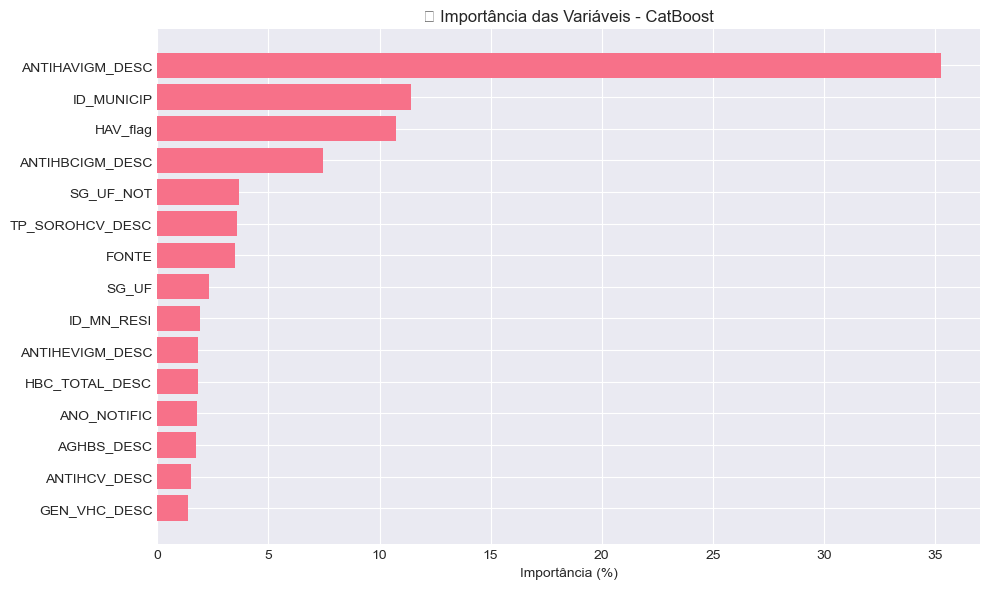

In [53]:
feature_importance = model.get_feature_importance(prettified=True)
feature_importance.rename(columns={"Importances": "Importance"}, inplace=True)
feature_importance = feature_importance.sort_values("Importance", ascending=False)

print("\n Top 15 features mais importantes:")
display(feature_importance.head(15))

# Gráfico das 15 mais importantes
plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature Id"][:15][::-1], feature_importance["Importance"][:15][::-1])
plt.title("🎯 Importância das Variáveis - CatBoost")
plt.xlabel("Importância (%)")
plt.tight_layout()
plt.show()

SHAP VALUES (EXPLICABILIDADE LOCAL E GLOBAL)

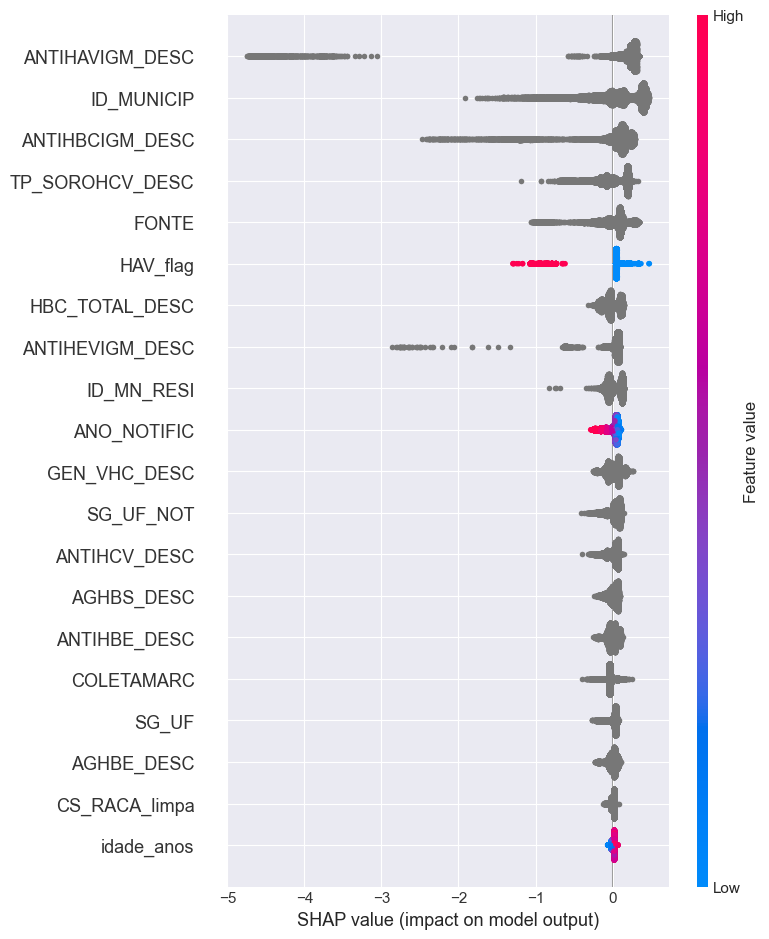

In [55]:
import shap
import plotly.express as px

# Cria o objeto explicador SHAP específico para CatBoost
explainer = shap.TreeExplainer(model)

# Calcula valores shap para o conjunto de teste
shap_values = explainer.shap_values(X_test)

# ===========================================
# 5️⃣ Gerar gráfico summary (importância + direção)
# ===========================================
shap.summary_plot(shap_values, X_test, plot_type="dot", show=True)


Grafico interativo para o Shap

In [57]:
shap_df = pd.DataFrame(shap_values, columns=X_test.columns)
shap_df["index"] = range(len(X_test))

# Formato longo (um ponto por amostra e feature)
long_df = shap_df.melt(id_vars="index", var_name="feature", value_name="shap_value")



# Adiciona os valores originais das features (para colorir)
vals_long = X_test.reset_index().melt(id_vars="index", var_name="feature", value_name="feature_value")

# Une os dois DataFrames (valores SHAP + valores originais)
df_plot = pd.merge(long_df, vals_long, on=["index", "feature"])


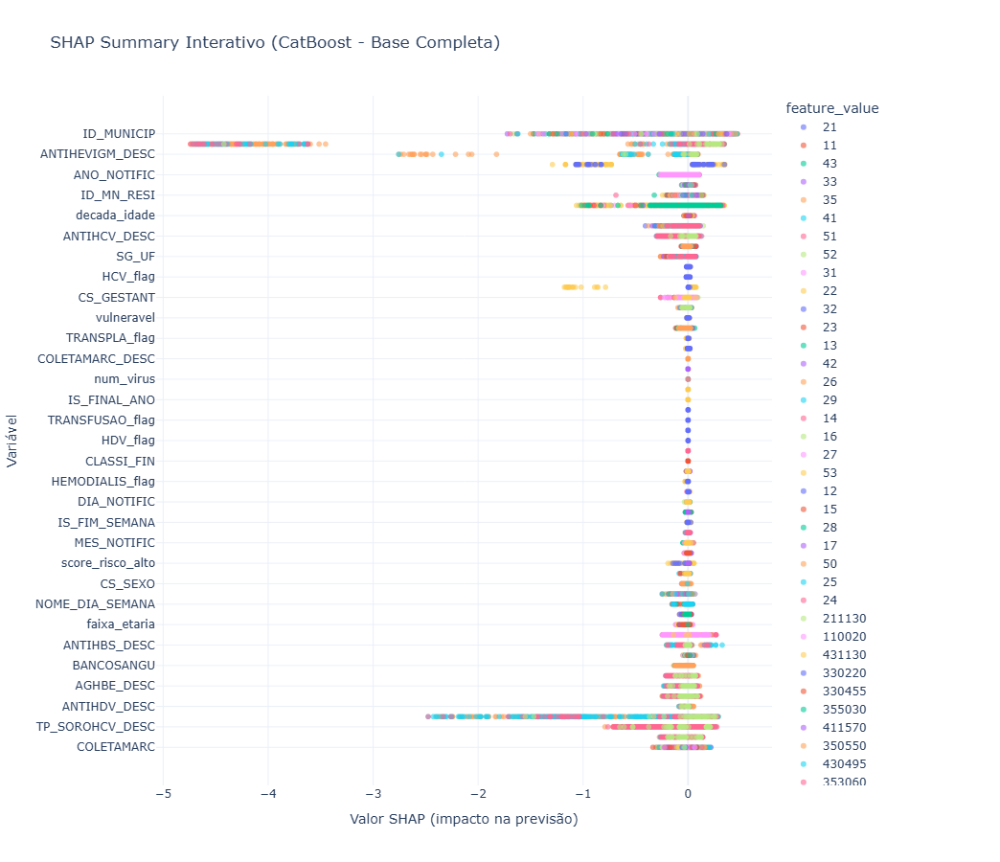

In [99]:

# ===========================================
# 5️⃣ Criar gráfico interativo tipo summary
# ===========================================
fig = px.scatter(
    df_plot,
    x="shap_value",
    y="feature",
    color="feature_value",
    color_continuous_scale="RdBu_r",
    title="SHAP Summary Interativo (CatBoost - Base Completa)",
    opacity=0.6,
    hover_data={"feature_value": True, "shap_value": True},
    height=900,
    width=900
)

fig.update_layout(
    xaxis_title="Valor SHAP (impacto na previsão)",
    yaxis_title="Variável",
    yaxis={'categoryorder':'total ascending'},
    coloraxis_colorbar=dict(title="Valor da variável"),
    template="plotly_white"
)

fig.show()
